<a href="https://colab.research.google.com/github/HedarBilgec/skills-introduction-to-github/blob/main/Hafta_3_Odev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Başlangıç: Örnek Görsellerin Oluşturulması
Görevleri gerçekleştirebilmek için öncelikle düşük kontrastlı ve gürültülü yapay gri tonlamalı (grayscale) görseller oluşturalım.

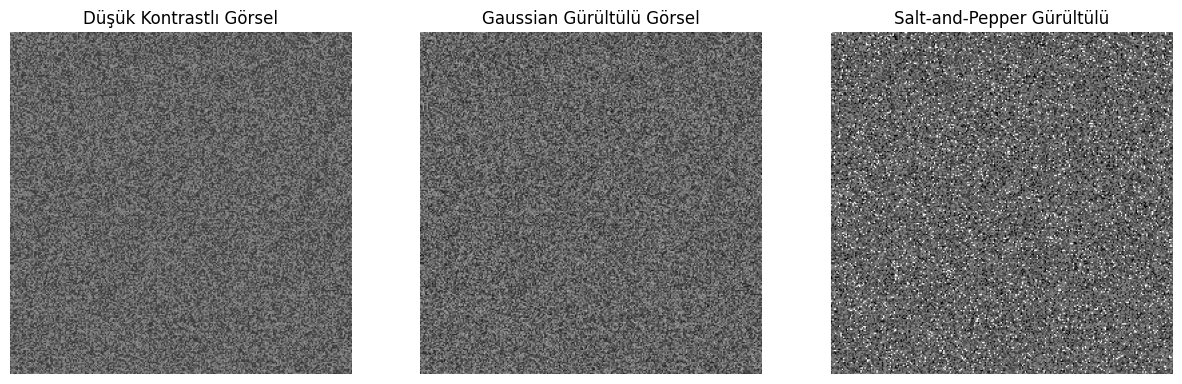

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Düşük Kontrastlı Görsel Oluşturma (Task-1, Task-2 ve Task-3 için)
# 0-255 aralığının sadece dar bir kısmını (örneğin 50-150 aralığını) kullanan bir görsel oluşturuyoruz.
np.random.seed(42)
low_contrast_img = np.random.randint(50, 150, size=(256, 256), dtype=np.uint8)

# 2. Gürültülü Görsel Oluşturma (Task-4 için Gaussian Gürültü)
gaussian_noise = np.random.normal(0, 15, (256, 256)).astype(np.float32)
noisy_img = np.clip(low_contrast_img.astype(np.float32) + gaussian_noise, 0, 255).astype(np.uint8)

# 3. Salt-and-Pepper Gürültülü Görsel Oluşturma (Task-5 için)
sp_noisy_img = low_contrast_img.copy()
# Salt (Tuz) gürültüsü
num_salt = np.ceil(0.05 * sp_noisy_img.size)
coords = [np.random.randint(0, i - 1, int(num_salt)) for i in sp_noisy_img.shape]
sp_noisy_img[tuple(coords)] = 255
# Pepper (Biber) gürültüsü
num_pepper = np.ceil(0.05 * sp_noisy_img.size)
coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in sp_noisy_img.shape]
sp_noisy_img[tuple(coords)] = 0

# Görselleri görselleştirelim
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(low_contrast_img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Düşük Kontrastlı Görsel")
axes[0].axis('off')

axes[1].imshow(noisy_img, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("Gaussian Gürültülü Görsel")
axes[1].axis('off')

axes[2].imshow(sp_noisy_img, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("Salt-and-Pepper Gürültülü")
axes[2].axis('off')

plt.show()

### Task-1: Doğrusal Parlaklık Ölçekleme (Kontrast Germe)

**Konu Anlatımı:**
Düşük kontrastlı görüntülerde piksel değerleri dar bir aralıkta sıkışmıştır. Bu durum detayların kaybolmasına yol açar. Görüntünün kontrastını artırmak için min-max normalizasyonu kullanarak pikselleri $[0, 255]$ aralığına doğrusal olarak genişletebiliriz:

$$I_{yeni} = \frac{I - I_{min}}{I_{max} - I_{min}} \times 255$$

Orijinal Görsel Min Değeri: 50.0, Max Değeri: 149.0


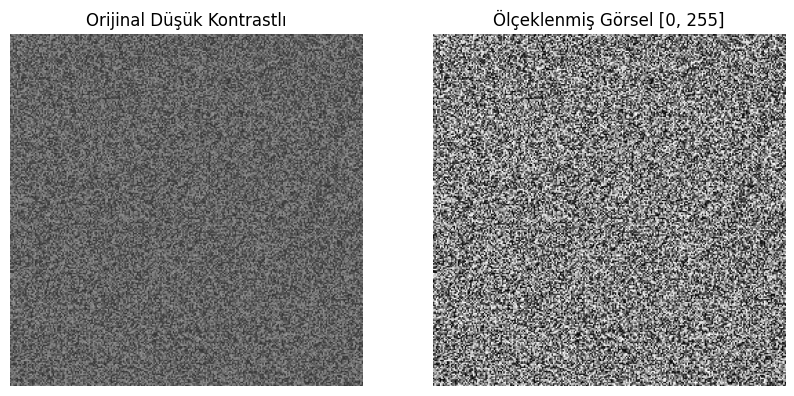

In [2]:
# Minimum ve maksimum değerleri bulma
img_min = float(np.min(low_contrast_img))
img_max = float(np.max(low_contrast_img))

print(f"Orijinal Görsel Min Değeri: {img_min}, Max Değeri: {img_max}")

# Doğrusal ölçekleme işlemi (Hazır fonksiyon kullanılmadan)
scaled_img = ((low_contrast_img.astype(np.float32) - img_min) / (img_max - img_min) * 255.0)
scaled_img = np.clip(scaled_img, 0, 255).astype(np.uint8)

# Görselleştirme
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(low_contrast_img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Orijinal Düşük Kontrastlı")
axes[0].axis('off')

axes[1].imshow(scaled_img, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("Ölçeklenmiş Görsel [0, 255]")
axes[1].axis('off')

plt.show()

### Task-2: Histogram Eşitleme (Histogram Equalization)

**Konu Anlatımı:**
Histogram eşitleme, görüntünün kontrastını piksellerin kümülatif dağılım fonksiyonunu (CDF) kullanarak dengeler. İşlem adımları:
1. 256 elemanlı histogramı manuel hesaplarız.
2. Histogram değerlerini toplayarak Kümülatif Dağılım Fonksiyonunu (CDF) elde ederiz.
3. CDF değerlerini $[0, 255]$ aralığına normalize ederek pikselleri yeni değerleriyle eşleştiririz.

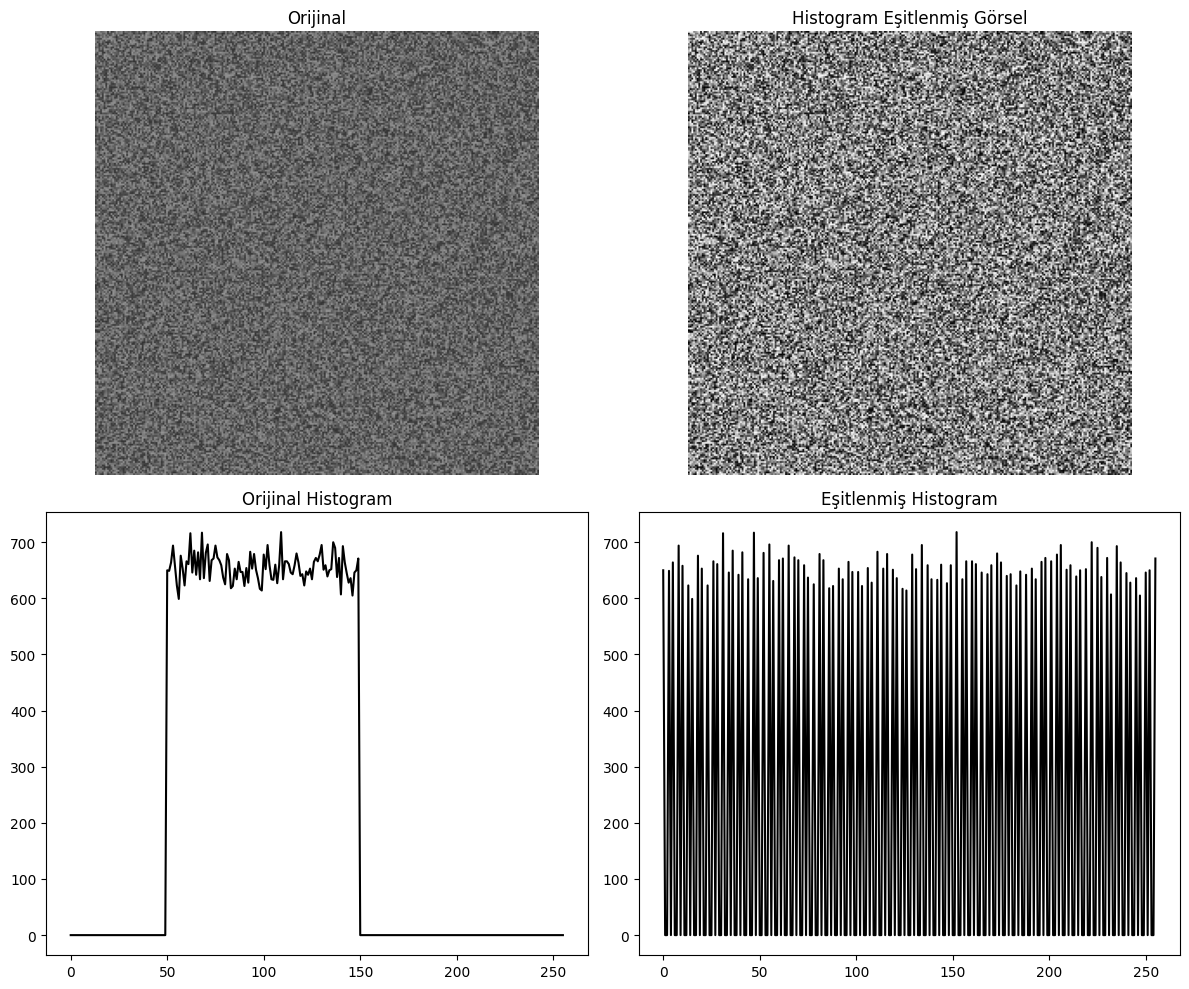

In [3]:
# 1. Manuel Histogram Hesaplama
hist = np.zeros(256, dtype=np.int32)
for val in low_contrast_img.ravel():
    hist[val] += 1

# 2. Manuel Kümülatif Dağılım Fonksiyonu (CDF) Hesaplama
cdf = np.zeros(256, dtype=np.int32)
current_sum = 0
for i in range(256):
    current_sum += hist[i]
    cdf[i] = current_sum

# 3. CDF Normalizasyonu ve Histogram Eşitleme
cdf_min = np.min(cdf[cdf > 0])
M, N = low_contrast_img.shape
# Formül: h(v) = round((cdf(v) - cdf_min) / ((M * N) - cdf_min) * 255)
equalized_lookup = np.zeros(256, dtype=np.uint8)
for i in range(256):
    if cdf[i] > 0:
        equalized_lookup[i] = np.round(((cdf[i] - cdf_min) / ((M * N) - cdf_min)) * 255.0)
    else:
        equalized_lookup[i] = 0

# Yeni görüntüyü oluşturma
equalized_img = equalized_lookup[low_contrast_img]

# Kaydetme
cv2.imwrite("equalized_output.png", equalized_img)

# Görselleştirme
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].imshow(low_contrast_img, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Orijinal")
axes[0, 0].axis('off')

axes[0, 1].imshow(equalized_img, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Histogram Eşitlenmiş Görsel")
axes[0, 1].axis('off')

axes[1, 0].plot(hist, color='black')
axes[1, 0].set_title("Orijinal Histogram")

# Eşitlenmiş yeni histogramı çizelim
new_hist = np.zeros(256, dtype=np.int32)
for val in equalized_img.ravel():
    new_hist[val] += 1
axes[1, 1].plot(new_hist, color='black')
axes[1, 1].set_title("Eşitlenmiş Histogram")

plt.tight_layout()
plt.show()

### Task-3: CLAHE (Contrast Limited Adaptive Histogram Equalization)

**Konu Anlatımı:**
Standart histogram eşitleme tüm görüntüye global olarak uygulanır ve bazen aşırı parlaklığa veya gürültünün artmasına neden olur. CLAHE ise görüntüyü küçük alt bölümlere ayırır (grid), her bölge için yerel histogram hesaplar ve kontrastı sınırlandırarak gürültü artışını engeller. Komşu bölgeler arasındaki geçişlerin yumuşak olması için çift doğrusal (bilinear) interpolasyon kullanılır.

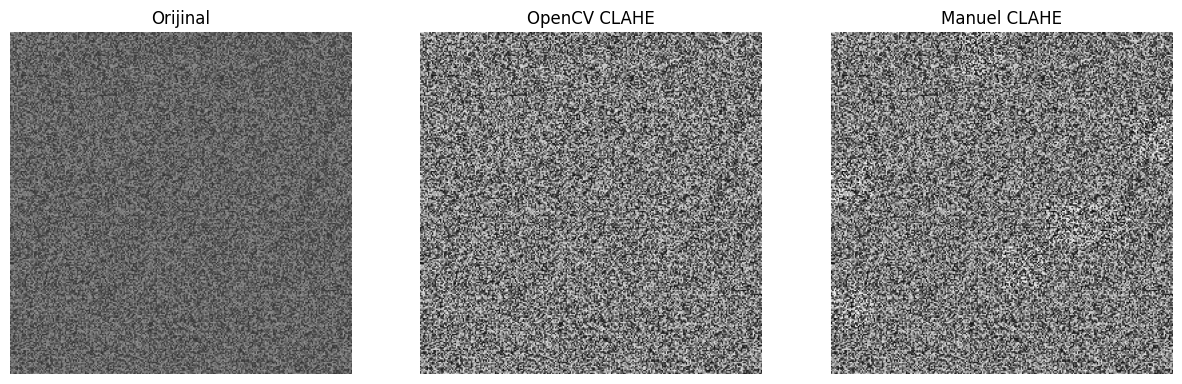

In [4]:
# 1. OpenCV Hazır CLAHE Fonksiyonu ile Çözüm
clahe_cv = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_img_cv = clahe_cv.apply(low_contrast_img)

# 2. Manuel CLAHE Gerçeklemesi (Basit Grid Temelli CDF Dağıtımı)
def manual_clahe(img, clip_limit=2.0, grid_size=(8, 8)):
    h, w = img.shape
    gh, gw = grid_size
    step_h, step_w = h // gh, w // gw

    # Her hücre için yerel histogram ve sınırlandırılmış CDF hesaplama
    cdfs = []
    for i in range(gh):
        row_cdfs = []
        for j in range(gw):
            grid_cell = img[i*step_h:(i+1)*step_h, j*step_w:(j+1)*step_w]
            # Histogram
            grid_hist, _ = np.histogram(grid_cell, bins=256, range=(0, 256))

            # Kontrast Sınırlandırma (Clip Limit)
            clip_val = int(clip_limit * (step_h * step_w) / 256)
            excess = 0
            for k in range(256):
                if grid_hist[k] > clip_val:
                    excess += grid_hist[k] - clip_val
                    grid_hist[k] = clip_val

            # Fazlalığı eşit dağıtma
            bin_incr = excess // 256
            grid_hist += bin_incr

            # CDF hesaplama
            grid_cdf = np.cumsum(grid_hist)
            grid_cdf = (grid_cdf - grid_cdf[0]) / (grid_cdf[-1] - grid_cdf[0]) * 255.0
            row_cdfs.append(grid_cdf.astype(np.uint8))
        cdfs.append(row_cdfs)

    # Hücreleri birleştiren basit interpolasyon eşlemesi
    out = np.zeros_like(img)
    for y in range(h):
        for x in range(w):
            # Hangi hücreye denk geldiğini bulalım
            grid_y = min(y // step_h, gh - 1)
            grid_x = min(x // step_w, gw - 1)
            val = img[y, x]
            out[y, x] = cdfs[grid_y][grid_x][val]
    return out

clahe_img_manual = manual_clahe(low_contrast_img, clip_limit=2.0, grid_size=(8,8))

# Karşılaştırma
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(low_contrast_img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Orijinal")
axes[0].axis('off')

axes[1].imshow(clahe_img_cv, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("OpenCV CLAHE")
axes[1].axis('off')

axes[2].imshow(clahe_img_manual, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("Manuel CLAHE")
axes[2].axis('off')

plt.show()

### Task-4: Konvolüsyon ile Ortalama (Mean) Filtresi

**Konu Anlatımı:**
Ortalama filtresi, bir piksellik çevresindeki 3x3 piksellerin ortalamasını alarak resmi pürüzsüzleştirir ve gürültüyü bastırır. 3x3 boyutundaki maskemiz şu şekildedir:

$$K = \frac{1}{9} \begin{bmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{bmatrix}$$

Görsel kenarlarda kayıp yaşamamak için kenar dolgusu (padding) uygulanır.

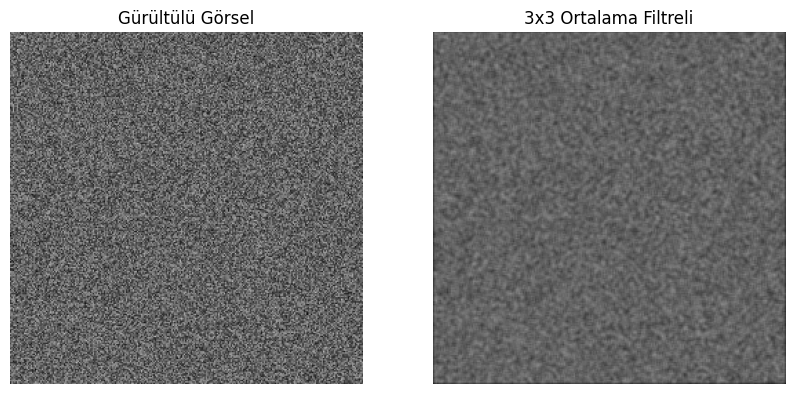

In [5]:
def mean_filter_3x3(img):
    h, w = img.shape
    # Zero padding (Sıfır Dolgusu)
    padded = np.pad(img, 1, mode='constant', constant_values=0)
    out = np.zeros_like(img)

    for y in range(h):
        for x in range(w):
            # 3x3 komşuluk alanını alıyoruz
            neighborhood = padded[y:y+3, x:x+3]
            # Ortalama hesaplama
            out[y, x] = np.mean(neighborhood)

    return out

filtered_img = mean_filter_3x3(noisy_img)

# Görselleştirme
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(noisy_img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Gürültülü Görsel")
axes[0].axis('off')

axes[1].imshow(filtered_img, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("3x3 Ortalama Filtreli")
axes[1].axis('off')

plt.show()

### Task-5: Medyan Filtre ile Salt-and-Pepper Gürültüsü Bastırma

**Konu Anlatımı:**
Salt-and-Pepper (tuz ve biber) gürültüsü piksellerin aniden maksimum (255) ya da minimum (0) değerlere sahip olmasından kaynaklanır. Doğrusal ortalama filtreleri bu gürültüyü yayar. Doğrusal olmayan bir filtre olan **Medyan Filtre** ise komşuluk alanındaki değerleri sıralayıp ortadaki (medyan) değeri seçtiği için bu tip gürültüleri mükemmel şekilde filtreler.

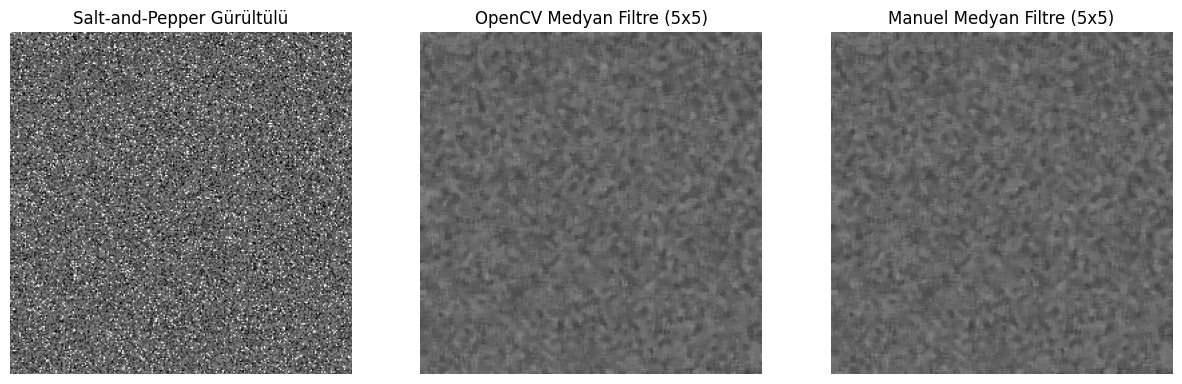

In [6]:
# 1. OpenCV Hazır Medyan Filtresi (5x5)
median_cv = cv2.medianBlur(sp_noisy_img, 5)

# 2. Manuel Medyan Filtresi (5x5)
def manual_median_filter_5x5(img):
    h, w = img.shape
    # 5x5 pencere için kenar dolgusu (padding = 2)
    padded = np.pad(img, 2, mode='reflect')
    out = np.zeros_like(img)

    for y in range(h):
        for x in range(w):
            # 5x5 bölgeyi çıkar
            neighborhood = padded[y:y+5, x:x+5]
            # Medyan değerini bulup yeni piksel olarak ata
            out[y, x] = np.median(neighborhood)

    return out

median_manual = manual_median_filter_5x5(sp_noisy_img)

# Görselleştirme ve Karşılaştırma
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sp_noisy_img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Salt-and-Pepper Gürültülü")
axes[0].axis('off')

axes[1].imshow(median_cv, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("OpenCV Medyan Filtre (5x5)")
axes[1].axis('off')

axes[2].imshow(median_manual, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("Manuel Medyan Filtre (5x5)")
axes[2].axis('off')

plt.show()